# Safaricom vs Airtel: Which gives better value for mobile data?

**My Problem Statement**

Mobile data is a daily expense for most Kenyans. Both Safaricom and Airtel advertise bigger bundles for the same price. This project compares their daily, weekly, and monthly bundles by **price per GB** to show which network actually offers better value.

**Who this is for**

I analyse two example people who both depend on mobile data:

1. **The remote worker** — a heavier user (~59 GB/month) who works from a phone or hotspot.
2. **The online student** — a lighter user (~23 GB/month) who learns online.

**Scope:** Standard daily, weekly, and monthly bundles from `*544#`. No 5G bundles, because most data in Kenya is still carried on 4G.

### My bias

**I am pro-Airtel.** I use Airtel personally and it works well where I live. I also find Safaricom's bundles overpriced — I'd rather get more data on Airtel for the same money. That's a preference, not a fact.

Where it might have shown up: the bundles I picked, how I framed the results, and which network I present as the winner.

What I did to limit it:

- I picked bundles that **cost the same on both networks**, so the only difference is what you get for your money.
- I left out one-off promotional bundles — they change too often to compare fairly.
- All the calculations are in this notebook, so you can check them.

I'm including this because my teacher asked for it, and because I think it's more honest than pretending I don't have a bias.

## Importing Necessary Libraries

In [7]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display

## The Scenario

Two Kenyans depend on mobile data every day because they have no WiFi:

- **The remote worker** — works from a phone or hotspot, upcountry
- **The online student** — learns online, also upcountry

Both have an Airtel SIM and a Safaricom SIM, so they can choose either network.

## The Question

**Which network gives better value for money?**

I answer in three parts:

1. At each price, which network gives more data?
2. For each person, which network costs less per month?
3. Which network has better 4G coverage where they live?

## Creating my Dataset

Source: USSD code `*544#` for both Airtel and Safaricom, as of **11 October 2026**. I chose bundles that share a price (e.g., both KES 250 weekly bundles) so the comparison is fair.

In [8]:
bundles = pd.DataFrame([
    # provider, bundle_name, price_kes, data_gb, validity
    ["Safaricom", "Sh99=1.5GB+40SMS+BAZE,24hrs",   99,  1.5, "daily"],
    ["Safaricom", "Sh99=1.1GB+Free YouTube 7day",  99,  1.1, "weekly"],
    ["Safaricom", "Sh250=3.2GB+Free YouTube 7day", 250, 3.2, "weekly"],
    ["Safaricom", "Sh500=11GB+Free YouTube 7day",  500, 11, "weekly"],
    ["Safaricom", "Sh250=2.5GB 30day",             250,  2.5, "monthly"],
    ["Safaricom", "Sh500=7GB+WhatsApp 30day",      500,  7, "monthly"],
    ["Safaricom", "Sh1000=21GB+WhatsApp 30day",   1000, 21, "monthly"],
    ["Safaricom", "Sh2000=45GB+WhatsApp 30day",   2000, 45, "monthly"],
    ["Airtel", "2.4GB+WhatsApp @99",      99,  2.4, "daily"],
    ["Airtel", "1.5GB+WhatsApp @100,7days",  100,  1.5, "weekly"],
    ["Airtel", "5GB+WhatsApp @250,7days",    250,  5, "weekly"],
    ["Airtel", "12GB+WhatsApp @500,7days",   500, 12, "weekly"],
    ["Airtel", "3GB @250",     250,  3, "monthly"],
    ["Airtel", "8GB @500",     500,  8, "monthly"],
    ["Airtel", "25GB @1000",  1000, 25, "monthly"],
    ["Airtel", "55GB @2000",  2000, 55, "monthly"],
], columns=["provider", "bundle_name", "price_kes", "data_gb", "validity"])

bundles.index = range(1, len(bundles) + 1)
bundles

,provider,bundle_name,price_kes,data_gb,validity
1,Safaricom,"Sh99=1.5GB+40SMS+BAZE,24hrs",99,1.5,daily
2,Safaricom,Sh99=1.1GB+Free YouTube 7day,99,1.1,weekly
3,Safaricom,Sh250=3.2GB+Free YouTube 7day,250,3.2,weekly
4,Safaricom,Sh500=11GB+Free YouTube 7day,500,11.0,weekly
5,Safaricom,Sh250=2.5GB 30day,250,2.5,monthly
6,Safaricom,Sh500=7GB+WhatsApp 30day,500,7.0,monthly
7,Safaricom,Sh1000=21GB+WhatsApp 30day,1000,21.0,monthly
8,Safaricom,Sh2000=45GB+WhatsApp 30day,2000,45.0,monthly
9,Airtel,2.4GB+WhatsApp @99,99,2.4,daily
10,Airtel,"1.5GB+WhatsApp @100,7days",100,1.5,weekly


In [9]:
# I add validity_days (1, 7, or 30) to each bundle.
# I use this later in Measure 3, where I work out how many bundles
# someone needs to cover a full 30 days.
validity_days = {"daily": 1, "weekly": 7, "monthly": 30}
bundles["validity_days"] = bundles["validity"].map(validity_days)

## My Measures

I use **four main measures**. Each one has a clear result.

| # | Measure | Question it answers | Result |
|---|---------|---------------------|--------|
| 1 | **Price per GB** | How much does each GB cost? | Airtel is cheaper in every tier. |
| 2 | **Head-to-head** | At the same price, who gives more? | Airtel gives 9–60% more data. |
| 3 | **Cost to cover the month** | What's the cheapest way to cover 30 days? | Airtel is KES 500–1,000 cheaper. |
| 4 | **Price per GB actually used** | What if you don't use all the data? | The gap widens for lighter users. |

I also look at **coverage** (4G towers per county) separately, because a cheap bundle is useless without signal.

### Measure 1: Price per GB

**What it shows:** How much each GB costs in KES. Lower is better.

**How I calculate it:** Price in KES ÷ data in GB.

In [10]:
# price per GB = price in KES divided by data in GB
bundles["price_per_gb"] = (bundles["price_kes"] / bundles["data_gb"]).round(2)

# show the three validity groups side by side, sorted cheapest first
for validity in ["daily", "weekly", "monthly"]:
    group = bundles[bundles["validity"] == validity].sort_values("price_per_gb").copy()
    group.index = range(1, len(group) + 1)
    print(f"\n{validity.upper()} BUNDLES — sorted by price per GB (cheapest first)")
    display(group[["provider", "bundle_name", "price_kes", "data_gb", "price_per_gb"]])


DAILY BUNDLES — sorted by price per GB (cheapest first)


,provider,bundle_name,price_kes,data_gb,price_per_gb
1,Airtel,2.4GB+WhatsApp @99,99,2.4,41.25
2,Safaricom,"Sh99=1.5GB+40SMS+BAZE,24hrs",99,1.5,66.00



WEEKLY BUNDLES — sorted by price per GB (cheapest first)


,provider,bundle_name,price_kes,data_gb,price_per_gb
1,Airtel,"12GB+WhatsApp @500,7days",500,12.0,41.67
2,Safaricom,Sh500=11GB+Free YouTube 7day,500,11.0,45.45
3,Airtel,"5GB+WhatsApp @250,7days",250,5.0,50.00
4,Airtel,"1.5GB+WhatsApp @100,7days",100,1.5,66.67
5,Safaricom,Sh250=3.2GB+Free YouTube 7day,250,3.2,78.12
6,Safaricom,Sh99=1.1GB+Free YouTube 7day,99,1.1,90.00



MONTHLY BUNDLES — sorted by price per GB (cheapest first)


,provider,bundle_name,price_kes,data_gb,price_per_gb
1,Airtel,55GB @2000,2000,55.0,36.36
2,Airtel,25GB @1000,1000,25.0,40.00
3,Safaricom,Sh2000=45GB+WhatsApp 30day,2000,45.0,44.44
4,Safaricom,Sh1000=21GB+WhatsApp 30day,1000,21.0,47.62
5,Airtel,8GB @500,500,8.0,62.50
6,Safaricom,Sh500=7GB+WhatsApp 30day,500,7.0,71.43
7,Airtel,3GB @250,250,3.0,83.33
8,Safaricom,Sh250=2.5GB 30day,250,2.5,100.00


#### Finding

Airtel is cheaper per GB in **every** tier.

| Tier | Safaricom (KES/GB) | Airtel (KES/GB) | Winner |
|------|-------------------|-----------------|--------|
| Daily KES 99 | 66.00 | 41.25 | Airtel |
| Weekly KES 99/100 | 90.00 | 66.67 | Airtel |
| Weekly KES 250 | 78.12 | 50.00 | Airtel |
| Weekly KES 500 | 45.45 | 41.67 | Airtel |
| Monthly KES 250 | 100.00 | 83.33 | Airtel |
| Monthly KES 500 | 71.43 | 62.50 | Airtel |
| Monthly KES 1,000 | 47.62 | 40.00 | Airtel |
| Monthly KES 2,000 | 44.44 | 36.36 | Airtel |

**The gap is widest at the low end** (daily and small weekly bundles) and **narrowest at the top** (the KES 500 weekly and KES 2,000 monthly bundles).

### Measure 2: Head-to-head

**What it shows:** How much data each network gives at the same price and validity.

**How I calculate it:** Airtel's GB ÷ Safaricom's GB − 1.

In [11]:
# treat Airtel's KES 100 weekly bundle and Safaricom's KES 99 as the same tier
bundles["price_tier"] = bundles["price_kes"].replace(100, 99)

h2h = bundles.pivot_table(index=["validity", "price_tier"], columns="provider", values="data_gb")
h2h = h2h.reset_index()
h2h.columns.name = None
h2h.columns = ["validity", "price_kes", "airtel_gb", "safaricom_gb"]
h2h["airtel_extra_%"] = ((h2h["airtel_gb"] / h2h["safaricom_gb"] - 1) * 100).round(1)

# show all three validity groups
for validity in ["daily", "weekly", "monthly"]:
    group = h2h[h2h["validity"] == validity].copy()
    group.index = range(1, len(group) + 1)
    print(f"\n{validity.upper()} — Airtel vs Safaricom at the same price")
    display(group)

# one-line summary for the slide
biggest = h2h.loc[h2h["airtel_extra_%"].idxmax()]
smallest = h2h.loc[h2h["airtel_extra_%"].idxmin()]
print(f"\nBiggest gap: {biggest['airtel_extra_%']}% on the {biggest['validity']} KES {biggest['price_kes']:.0f} bundle")
print(f"Smallest gap: {smallest['airtel_extra_%']}% on the {smallest['validity']} KES {smallest['price_kes']:.0f} bundle")


DAILY — Airtel vs Safaricom at the same price


,validity,price_kes,airtel_gb,safaricom_gb,airtel_extra_%
1,daily,99,2.4,1.5,60.0



WEEKLY — Airtel vs Safaricom at the same price


,validity,price_kes,airtel_gb,safaricom_gb,airtel_extra_%
1,weekly,99,1.5,1.1,36.4
2,weekly,250,5.0,3.2,56.2
3,weekly,500,12.0,11.0,9.1



MONTHLY — Airtel vs Safaricom at the same price


,validity,price_kes,airtel_gb,safaricom_gb,airtel_extra_%
1,monthly,250,3.0,2.5,20.0
2,monthly,500,8.0,7.0,14.3
3,monthly,1000,25.0,21.0,19.0
4,monthly,2000,55.0,45.0,22.2



Biggest gap: 60.0% on the daily KES 99 bundle
Smallest gap: 9.1% on the weekly KES 500 bundle


#### Finding

Airtel gives more data at **every** price tier, but the gap varies a lot.

| Gap size | Where | Example |
|----------|-------|---------|
| **Biggest: 60%** | Daily KES 99 | Airtel 2.4 GB vs Safaricom 1.5 GB |
| **Smallest: 9%** | Weekly KES 500 | Airtel 12 GB vs Safaricom 11 GB |

The **average gap** across all tiers is about 34%. The **median gap** is about 21%.

**Where Airtel's lead is biggest:** the daily bundle and the KES 250 weekly bundle.
**Where Airtel's lead is smallest:** the KES 500 weekly bundle — only 9% more.

### Scenario 1: The Remote Worker

A working Kenyan upcountry with no WiFi, working from a phone or hotspot.

**Monthly need: about 59 GB**
- Browsing, email, cloud documents: 0.5 GB/day × 30 days = 15 GB
- Video calls: 2 hours/day × 22 working days × 1 GB/hour = 44 GB

The 1 GB/hour figure is a planning figure. Zoom's actual use ranges from 0.5 to 2.4 GB/hour.

### Scenario 2: The Online Student

A student learning online with no WiFi.

**Monthly need: about 23 GB**
- Notes, email, platform, downloads: 0.3 GB/day × 30 days = 9 GB
- Live classes: 1 hour × 8 days × 1 GB/hour = 8 GB
- Recorded lectures: 1 hour × 12 days × 0.5 GB/hour = 6 GB

This is well above the national average of 5–6 GB/month, because the student depends on mobile data for study.

### Measure 3: Cost to cover the month

**What it shows:** The cheapest way for each network to cover 30 days of data, for each persona.

**How I calculate it:** For each bundle, I work out how many I'd need to buy to cover **both** the days (30 days of access) and the data (the person's monthly GB need). Whichever needs more bundles, that's the number.

In [12]:
browsing_gb_per_day = 0.5
call_gb_per_hour = 1.0
call_hours_per_day = 2
working_days = 22

worker_need_gb = 30 * browsing_gb_per_day + working_days * call_hours_per_day * call_gb_per_hour
print(f"The remote worker needs about {worker_need_gb:.1f} GB a month")

The remote worker needs about 59.0 GB a month


In [13]:
student_browsing_gb_per_day = 0.3
live_class_gb_per_hour = 1.0
live_class_hours_per_day = 1
live_class_days = 8
recorded_gb_per_hour = 0.5
recorded_hours_per_day = 1
recorded_days = 12

student_need_gb = (30 * student_browsing_gb_per_day
                   + live_class_days * live_class_hours_per_day * live_class_gb_per_hour
                   + recorded_days * recorded_hours_per_day * recorded_gb_per_hour)
print(f"The online student needs about {student_need_gb:.1f} GB a month")

The online student needs about 23.0 GB a month


I start by defining a function that costs every bundle for a given monthly need. For each bundle, it works out:

- **`bundles_for_days`** — how many to buy to cover 30 days (daily → 30, weekly → 5, monthly → 1)
- **`bundles_for_data`** — how many to buy to cover the GB need
- **`bundles_needed`** — the **larger** of the two, since both must be covered
- **`total_cost`** and **`total_gb`** — what you'd pay and what you'd get

In [14]:
# Define a function that, for a given monthly data need, works out
# how many bundles of each type someone would need to buy to cover 30 days.
def cost_to_cover(need_gb):
    df = bundles.copy()

    # how many to buy to cover 30 days of access
    df["bundles_for_days"] = np.ceil(30 / df["validity_days"])

    # how many to buy to cover the GB need
    df["bundles_for_data"] = np.ceil(need_gb / df["data_gb"])

    # you need enough to cover both, so take the larger number
    df["bundles_needed"] = np.maximum(df["bundles_for_days"], df["bundles_for_data"]).astype(int)

    # total cost and total GB for that many bundles
    df["total_cost"] = df["bundles_needed"] * df["price_kes"]
    df["total_gb"] = (df["bundles_needed"] * df["data_gb"]).round(1)

    return df

Now I run the function for the **remote worker** (59 GB/month). This shows all 16 bundles with their cost to cover 30 days, sorted cheapest first — not just the winners.

For each bundle I show:
- **`bundles_needed`** — how many of this bundle to buy
- **`total_cost`** — total spend for the month
- **`total_gb`** — total data bought

In [15]:
# Run the function for the remote worker
worker = cost_to_cover(worker_need_gb)

# Keep only the columns we want to see, sort cheapest first
worker_view = worker[["provider", "bundle_name", "validity",
                      "bundles_needed", "total_cost", "total_gb"]]
worker_view = worker_view.sort_values("total_cost").reset_index(drop=True)

# Show the full table
worker_view

,provider,bundle_name,validity,bundles_needed,total_cost,total_gb
0,Airtel,"12GB+WhatsApp @500,7days",weekly,5,2500,60.0
1,Airtel,2.4GB+WhatsApp @99,daily,30,2970,72.0
2,Safaricom,Sh500=11GB+Free YouTube 7day,weekly,6,3000,66.0
3,Safaricom,Sh1000=21GB+WhatsApp 30day,monthly,3,3000,63.0
4,Airtel,25GB @1000,monthly,3,3000,75.0
5,Airtel,"5GB+WhatsApp @250,7days",weekly,12,3000,60.0
6,Safaricom,"Sh99=1.5GB+40SMS+BAZE,24hrs",daily,40,3960,60.0
7,Safaricom,Sh2000=45GB+WhatsApp 30day,monthly,2,4000,90.0
8,Airtel,"1.5GB+WhatsApp @100,7days",weekly,40,4000,60.0
9,Airtel,8GB @500,monthly,8,4000,64.0


Same calculation for the **online student** (23 GB/month).

The student needs less data, so some bundles that didn't work for the worker might work better here — and vice versa.

In [16]:
# Run the function for the online student
student = cost_to_cover(student_need_gb)

# Same columns as the worker table, sorted cheapest first
student_view = student[["provider", "bundle_name", "validity",
                        "bundles_needed", "total_cost", "total_gb"]]
student_view = student_view.sort_values("total_cost").reset_index(drop=True)

# Show the full table
student_view

,provider,bundle_name,validity,bundles_needed,total_cost,total_gb
0,Airtel,25GB @1000,monthly,1,1000,25.0
1,Airtel,"5GB+WhatsApp @250,7days",weekly,5,1250,25.0
2,Airtel,8GB @500,monthly,3,1500,24.0
3,Airtel,"1.5GB+WhatsApp @100,7days",weekly,16,1600,24.0
4,Safaricom,Sh250=3.2GB+Free YouTube 7day,weekly,8,2000,25.6
5,Safaricom,Sh2000=45GB+WhatsApp 30day,monthly,1,2000,45.0
6,Safaricom,Sh1000=21GB+WhatsApp 30day,monthly,2,2000,42.0
7,Safaricom,Sh500=7GB+WhatsApp 30day,monthly,4,2000,28.0
8,Airtel,3GB @250,monthly,8,2000,24.0
9,Airtel,55GB @2000,monthly,1,2000,55.0


Finally, I filter to the cheapest option per network, per persona.

For each persona and network, I sort by cheapest total cost, and if two options cost the same I pick the one with more GB. Then I keep only the top row per provider.

In [17]:
# For each persona, print the cheapest option per network
for persona, df, need in [("Remote worker", worker, worker_need_gb),
                          ("Online student", student, student_need_gb)]:
    print(f"\n{persona.upper()} (needs {need:.0f} GB/month)")

    # sort by total cost (cheapest first), then by GB (most first), and keep top row per provider
    best = (df.sort_values(["total_cost", "total_gb"], ascending=[True, False])
              .groupby("provider")
              .first())

    # print in a fixed order so Safaricom is always first
    for provider in ["Safaricom", "Airtel"]:
        row = best.loc[provider]
        print(f"  {provider}: KES {row['total_cost']:,.0f} "
              f"({int(row['bundles_needed'])} × {row['bundle_name']}, {row['total_gb']:.1f} GB)")


REMOTE WORKER (needs 59 GB/month)
  Safaricom: KES 3,000 (6 × Sh500=11GB+Free YouTube 7day, 66.0 GB)
  Airtel: KES 2,500 (5 × 12GB+WhatsApp @500,7days, 60.0 GB)

ONLINE STUDENT (needs 23 GB/month)
  Safaricom: KES 2,000 (1 × Sh2000=45GB+WhatsApp 30day, 45.0 GB)
  Airtel: KES 1,000 (1 × 25GB @1000, 25.0 GB)


And the same result as a chart — Safaricom (green) vs Airtel (red), for each persona.

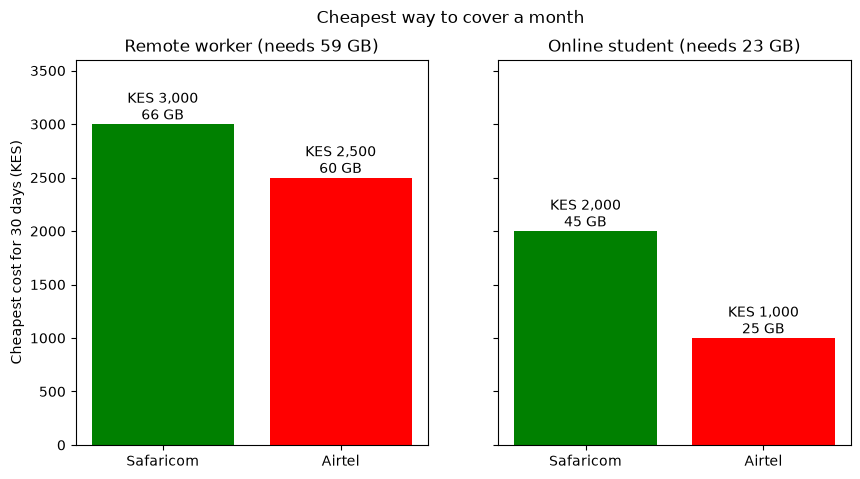

In [18]:
# Reuse the "cheapest per network" logic from the previous cell,
# but keep it in a DataFrame we can plot instead of printing it.
best_worker = (worker.sort_values(["total_cost", "total_gb"], ascending=[True, False])
                     .groupby("provider").first()
                     .loc[["Safaricom", "Airtel"]])
best_student = (student.sort_values(["total_cost", "total_gb"], ascending=[True, False])
                      .groupby("provider").first()
                      .loc[["Safaricom", "Airtel"]])

# Draw two side-by-side bar charts
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)

for ax, best, title in [(axes[0], best_worker, f"Remote worker (needs {worker_need_gb:.0f} GB)"),
                        (axes[1], best_student, f"Online student (needs {student_need_gb:.0f} GB)")]:
    bars = ax.bar(best.index, best["total_cost"], color=["green", "red"])
    # label each bar with the cost and the GB
    ax.bar_label(bars, labels=[f"KES {c:,.0f}\n{g:.0f} GB"
                               for c, g in zip(best["total_cost"], best["total_gb"])])
    ax.margins(y=0.2)
    ax.set_title(title)

axes[0].set_ylabel("Cheapest cost for 30 days (KES)")
plt.suptitle("Cheapest way to cover a month")
plt.show()

#### Finding

Airtel is cheaper for both personas.

| Persona | Safaricom | Airtel | Airtel saves |
|---------|-----------|--------|--------------|
| Remote worker (59 GB) | KES 3,000 | KES 2,500 | **KES 500 (17%)** |
| Online student (23 GB) | KES 2,000 | KES 1,000 | **KES 1,000 (50%)** |

**Why the student saves more:** Safaricom's cheapest monthly bundle that covers 23 GB is 45 GB — nearly double what they need. Airtel's 25 GB bundle is a much closer fit, so less money is wasted.

### Measure 4: Price per GB actually used

**What it shows:** How much you pay per GB you *actually use* — not per GB you buy.

**How I calculate it:** Total cost ÷ GB needed.

**Limit:** It depends on my usage estimates, so it's a comparison, not an exact figure.

In [19]:
# for each persona and network, find the cheapest option and compute price per GB used
def price_per_gb_used(need_gb, provider):
    df = cost_to_cover(need_gb)
    df = df[df["provider"] == provider]
    best = df.sort_values(["total_cost", "total_gb"], ascending=[True, False]).iloc[0]
    return best["total_cost"], best["total_gb"], best["total_cost"] / need_gb

rows = []
for persona, need in [("Remote worker", worker_need_gb), ("Online student", student_need_gb)]:
    for provider in ["Safaricom", "Airtel"]:
        cost, bought, used = price_per_gb_used(need, provider)
        rows.append([persona, provider, need, bought, cost, round(cost / bought, 2), round(used, 2)])

used = pd.DataFrame(rows, columns=["persona", "provider", "gb_needed", "gb_bought",
                                    "total_cost", "price_per_gb_bought", "price_per_gb_used"])
for persona, group in used.groupby("persona", sort=False):
    print(f"\n{persona.upper()}")
    display(group.drop(columns="persona"))


REMOTE WORKER


,provider,gb_needed,gb_bought,total_cost,price_per_gb_bought,price_per_gb_used
0,Safaricom,59.0,66.0,3000,45.45,50.85
1,Airtel,59.0,60.0,2500,41.67,42.37



ONLINE STUDENT


,provider,gb_needed,gb_bought,total_cost,price_per_gb_bought,price_per_gb_used
2,Safaricom,23.0,45.0,2000,44.44,86.96
3,Airtel,23.0,25.0,1000,40.00,43.48


#### Finding

For the **remote worker**, the advertised price and the real price are close. For the **online student**, they are very different on Safaricom.

| Persona | Provider | GB bought | GB used | Price/GB bought | Price/GB used | Waste |
|---------|----------|-----------|---------|-----------------|---------------|-------|
| Remote worker | Safaricom | 66 | 59 | 45.45 | 50.85 | 11% |
| Remote worker | Airtel | 60 | 59 | 41.67 | 42.37 | 2% |
| **Online student** | **Safaricom** | **45** | **23** | **44.44** | **86.96** | **96%** |
| Online student | Airtel | 25 | 23 | 40.00 | 43.48 | 9% |

The student's Safaricom bundle nearly doubles the real cost per GB, because almost half the data goes unused.

## Coverage: where does each network have 4G towers?

Price is only half of value for money. A cheap bundle is no use if there is no signal.

I count the **4G (LTE) cells each network has in each county**, using OpenCelliD tower locations and a county boundary map.

### Step 1: Load the county boundaries

Kenya has 47 counties. I load the shapefile and check the name column.

In [29]:
# Data source: Kenya county boundaries (47 counties), file County.shp.
counties = gpd.read_file("Data/kenyan-counties/County.shp")
counties = counties.to_crs("EPSG:4326")   # lat/long, to match the tower file

county_col = "COUNTY"   # the column that holds county names
print(f"Loaded {len(counties)} counties")
print(f"First three: {', '.join(counties[county_col].head(3))}")

Loaded 47 counties
First three: Turkana, Marsabit, Mandera


### Step 2: Load the 4G tower data

OpenCelliD's file for Kenya (country code 639). I keep only 4G (LTE) towers, then map network codes: **2 = Safaricom, 3 = Airtel**.

In [28]:
# Data source: OpenCelliD (opencellid.org). File: 639.csv.gz (Kenya).
# No header row, so I name the columns myself.
cols = ["radio", "mcc", "net", "area", "cell", "unit", "lon", "lat",
        "range", "samples", "changeable", "created", "updated", "averageSignal"]

chunks = []
for chunk in pd.read_csv("Data/kenyan-counties/639.csv.gz",
                         header=None, names=cols,
                         usecols=["radio", "mcc", "net", "lon", "lat"],
                         chunksize=1_000_000):
    keep = chunk[(chunk["mcc"] == 639) & (chunk["radio"] == "LTE")]
    chunks.append(keep)

towers = pd.concat(chunks, ignore_index=True)

# network codes: 2 = Safaricom, 3 = Airtel
towers["provider"] = towers["net"].map({2: "Safaricom", 3: "Airtel"})
towers = towers.dropna(subset=["provider"])

print(f"Loaded {len(towers):,} Kenyan 4G towers")
print(towers["provider"].value_counts().to_string())

Loaded 5,859 Kenyan 4G towers
provider
Safaricom    4314
Airtel       1545


### Step 3: Count towers per county

I turn each tower into a point, then assign it to the county it falls inside using a spatial join.

In [22]:
# turn each tower into a point on the map
tower_points = gpd.GeoDataFrame(
    towers,
    geometry=gpd.points_from_xy(towers["lon"], towers["lat"]),
    crs="EPSG:4326",
)

# spatial join: give each tower the county it falls inside
joined = gpd.sjoin(tower_points, counties[[county_col, "geometry"]],
                   how="inner", predicate="within")

# count towers per county, per provider
tower_counts = joined.groupby([county_col, "provider"]).size().unstack(fill_value=0)
tower_counts = tower_counts.reindex(counties[county_col].unique(), fill_value=0)
tower_counts = tower_counts[["Safaricom", "Airtel"]]

print(f"Towers assigned to a county: {len(joined):,}")
print(f"Counties with at least one tower: {(tower_counts.sum(axis=1) > 0).sum()} of {len(tower_counts)}")

Towers assigned to a county: 5,856
Counties with at least one tower: 34 of 47


### Step 4: Compute towers per 1,000 km²

I use an equal-area projection (EPSG:6933) so large and small counties are measured fairly. Then I divide towers by area.

In [23]:
# area in square km, using an equal-area projection so sizes are fair
counties["area_km2"] = counties.to_crs("EPSG:6933").area / 1_000_000

# merge counties with tower counts
coverage = counties.merge(tower_counts, left_on=county_col, right_index=True)

# towers per 1,000 km² for each network
for name in ["Safaricom", "Airtel"]:
    coverage[f"{name}_per_1000km2"] = (coverage[name] / coverage["area_km2"] * 1000).round(2)

coverage["total_towers"] = coverage["Safaricom"] + coverage["Airtel"]

# summary
print("Coverage summary")
print("-" * 50)
print(f"Counties with Safaricom towers: {(coverage['Safaricom'] > 0).sum()} of {len(coverage)}")
print(f"Counties with Airtel towers:    {(coverage['Airtel'] > 0).sum()} of {len(coverage)}")
print(f"Counties where Safaricom has more towers: {(coverage['Safaricom'] > coverage['Airtel']).sum()}")
print(f"Counties where Airtel has more towers:    {(coverage['Airtel'] > coverage['Safaricom']).sum()}")

Coverage summary
--------------------------------------------------
Counties with Safaricom towers: 34 of 47
Counties with Airtel towers:    25 of 47
Counties where Safaricom has more towers: 32
Counties where Airtel has more towers:    2


### Step 5: Visualise coverage

Two side-by-side maps. Green = Safaricom, red = Airtel. I use the same colour scale for both so they're comparable.

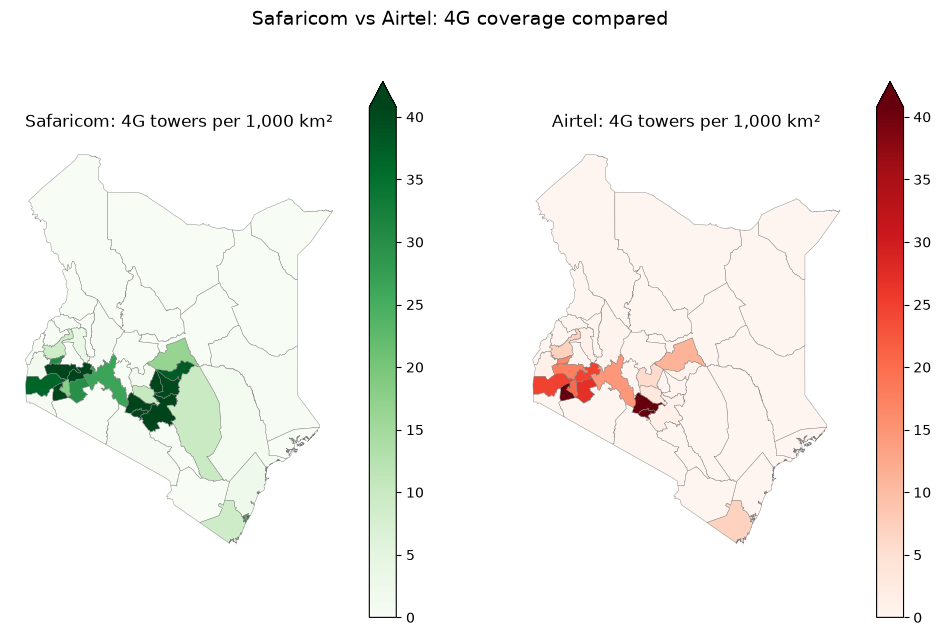

In [24]:
both = pd.concat([coverage["Safaricom_per_1000km2"], coverage["Airtel_per_1000km2"]])
top = np.percentile(both, 90)   # cap colour scale so Nairobi doesn't wash everything out

fig, axes = plt.subplots(1, 2, figsize=(12, 7))

coverage.plot(column="Safaricom_per_1000km2", cmap="Greens", vmin=0, vmax=top,
              legend=True, edgecolor="grey", linewidth=0.3, ax=axes[0])
axes[0].set_title("Safaricom: 4G towers per 1,000 km²")

coverage.plot(column="Airtel_per_1000km2", cmap="Reds", vmin=0, vmax=top,
              legend=True, edgecolor="grey", linewidth=0.3, ax=axes[1])
axes[1].set_title("Airtel: 4G towers per 1,000 km²")

for ax in axes:
    ax.axis("off")

plt.suptitle("Safaricom vs Airtel: 4G coverage compared", fontsize=14)
plt.show()

### Step 6: Which counties have the most towers?

A horizontal bar chart, showing only the **top 15 counties** so it's readable on a slide.

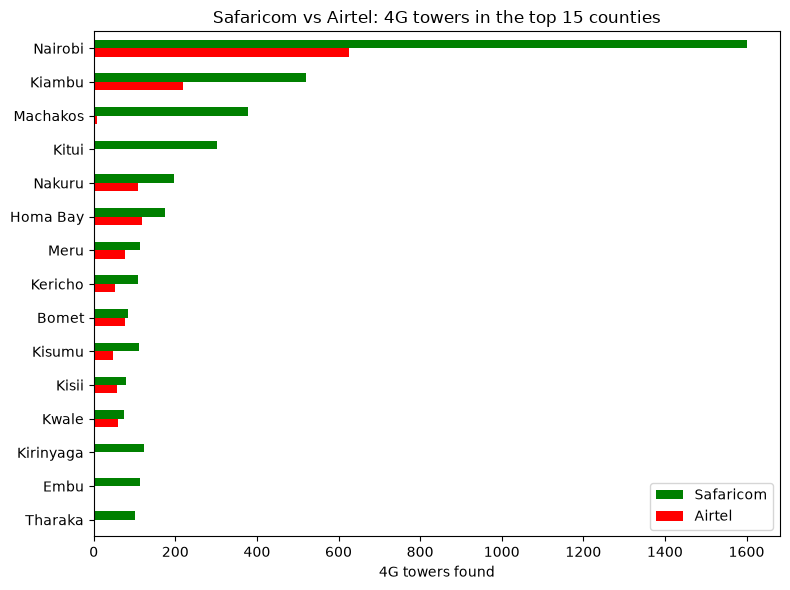

In [25]:
# top 15 counties by total towers
top15 = coverage.nlargest(15, "total_towers").set_index(county_col)[["Safaricom", "Airtel"]]

ax = top15.plot(kind="barh", color=["green", "red"], figsize=(8, 6))
ax.invert_yaxis()   # largest at the top
ax.set_xlabel("4G towers found")
ax.set_ylabel("")
ax.set_title("Safaricom vs Airtel: 4G towers in the top 15 counties")
plt.tight_layout()
plt.show()

#### Finding

Safaricom has 4G towers in **34 of 47 counties**; Airtel in **25**.

Safaricom has **more towers in 32 counties**; Airtel has more in only **2**.

Counties with no towers found are probably data gaps, not places without signal.

## Context: who this analysis is for, and who it isn't

Everything up to this point assumes one kind of user: someone with a **4G smartphone** who can buy data bundles from `*544#`. That is a real and growing group in Kenya — but it is not everyone.

This section looks at who is **left out** of the analysis, and what that means for the results.

### Device access in Kenya

Almost every Kenyan household has a mobile phone:

- **93.8%** of households own at least one mobile phone
- **95.8%** use at least one mobile phone

But **owning a phone is not the same as owning a smartphone**. As of December 2025, Kenya had **78.3 million mobile phones** connected to its networks:

- **48.7 million smartphones**
- **29.6 million feature phones**

Feature phones can call, text, and use mobile money, but they can't stream video, use most apps, or make full use of a data bundle. So while almost everyone has a phone, only about **62%** of those devices are smartphones — the kind this analysis assumes.

**Source:** Communications Authority of Kenya, Q2 2025/26 Sector Statistics Report (December 2025).

### Network generation: not everyone is on 4G

My analysis is built on 4G bundles, because most mobile data in Kenya is carried on 4G. But that doesn't mean everyone is on 4G.

As of December 2025, Kenya's mobile data subscriptions were:

| Network | Subscriptions | Share |
|---------|---------------|-------|
| **4G** | 44.2 million | 71.2% |
| **2G** | 10.4 million | 16.8% |
| **3G** | 5.7 million | 9.1% |
| **5G** | 1.7 million | 2.8% |

So **4G is the clear majority** — about 44 million of 62 million data subscriptions. But more than **16 million people** are still on 2G or 3G. Many of them:

- Live in rural or remote areas where 4G hasn't reached yet
- Use older or cheaper phones that don't support 4G
- Buy smaller bundles because bigger ones don't fit their use case or budget

When I compare Safaricom and Airtel on 4G bundles, I'm comparing what's best for the **majority** of smartphone users — not for everyone.

**Source:** Communications Authority of Kenya, Q2 2025/26 Sector Statistics Report (December 2025).

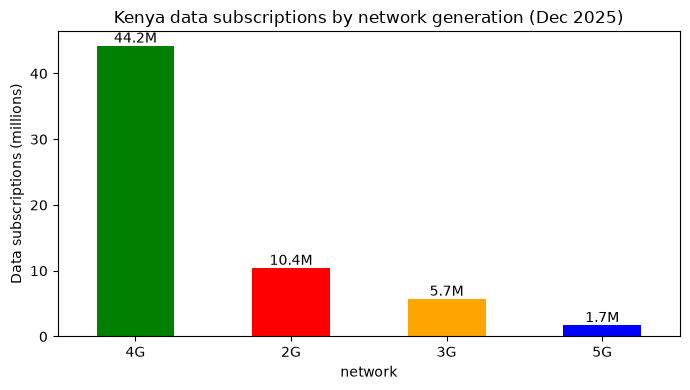

In [26]:
# These figures come from the Communications Authority of Kenya's
# Q2 2025/26 Sector Statistics Report (December 2025).
# https://www.ca.go.ke/
subscriptions = pd.DataFrame({
    "network": ["4G", "2G", "3G", "5G"],
    "millions": [44.2, 10.4, 5.7, 1.7],
})

# Bar chart so the reader can see the divide at a glance
ax = subscriptions.plot(kind="bar", x="network", y="millions",
                        color=["green", "red", "orange", "blue"],
                        legend=False, figsize=(7, 4))
ax.set_ylabel("Data subscriptions (millions)")
ax.set_title("Kenya data subscriptions by network generation (Dec 2025)")
ax.bar_label(ax.containers[0], labels=[f"{v}M" for v in subscriptions["millions"]])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### County bias: the digital divide

Even among people who do have 4G smartphones, the experience is not the same across Kenya. The most underserved counties are in the north and northeast, and along parts of the coast.

The counties with the **lowest mobile phone ownership**:

| County | Households with a mobile phone |
|--------|-------------------------------|
| West Pokot | 29.0% |
| Turkana | 29.4% |
| Marsabit | 34.8% |
| Tana River | 35.5% |
| Samburu | 36.8% |

The counties with the **lowest internet usage**:

| County | Households using the internet |
|--------|-------------------------------|
| West Pokot | 9.1% |
| Turkana | 12.7% |
| Tana River | 15.5% |
| Marsabit | 16.3% |
| Garissa | 16.5% |

Compare these to the national leaders:

- **Nairobi:** 64.7% internet usage
- **Kiambu:** 54.0%
- **Nyeri:** 50.1%

So a household in Nairobi is **about 7 times more likely** to use the internet than a household in West Pokot.

This divide overlaps with what I found in my coverage section: Safaricom has 4G towers in 34 of 47 counties, and the missing counties are often the same ones listed above.

### What this means for my analysis

My findings apply most directly to **one kind of user**: someone with a 4G smartphone, with coverage where they live, buying standard daily, weekly, or monthly bundles.

For everyone else, the picture is more complicated:

- **Feature phone users** (about 29.6 million) can't use these bundles the same way — no video, no apps, no full value from a GB-based bundle.
- **2G and 3G users** (about 16 million) buy smaller bundles and use less data. My analysis doesn't cover their options.
- **People in underserved counties** — Turkana, West Pokot, Marsabit, Garissa, and others — pay the same prices but may get worse signal. So the same bundle is worth less to them.

So when I say "Airtel gives more data per shilling," that's true for the bundles I compared and the users I assumed. It isn't automatically true for every Kenyan.

## Conclusion

**Airtel wins on price:**

- Cheaper per GB in every tier
- Gives 9–60% more data at the same price
- Costs KES 500–1,000 less per month to cover a real person's needs

**Safaricom wins on coverage:**

- 4G towers in 34 of 47 counties, compared to Airtel's 25
- More towers in 32 counties, compared to Airtel's 2

**The real answer:** It depends on where you live and who you are.

- If you have good Airtel signal and a 4G smartphone, Airtel gives you better value.
- If you live in a county where Airtel is weak, Safaricom's higher prices buy you coverage.
- If you're on a feature phone or an older network, neither of these bundles may fit your needs.

The price comparison is clear, but the value depends on circumstances this analysis can't fully capture.